# Chapitre 6 - Exercices 6.1 à 6.6

Ce notebook traite six exercices sur la partie RAG du chapitre 6 :

- **6.1** : long contexte ou RAG ? coût et latence chiffrés pour une base documentaire ;
- **6.2** : TF-IDF et BM25 à la main sur un mini-corpus, et le « bourrage de mots-clés » ;
- **6.3** : dimensionner un index vectoriel de 50 millions de passages (mémoire et calcul) ;
- **6.4** : calculer précision, rappel, MRR, MAP et NDCG à la main ;
- **6.5** : RRF contre fusion linéaire : invariance, réglage honnête de α, rôle de k ;
- **6.6** : taille des morceaux à budget de contexte fixé (mini-lab).

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import math
import warnings

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
Q = c6.QUESTIONS

## Exercice 6.1 : Long contexte ou RAG ?

**Énoncé.** Une entreprise veut un assistant sur sa documentation interne : $B = 400\,000$
tokens. Elle prévoit $R = 50\,000$ requêtes par jour, avec des réponses de 200 tokens. Prix
(fictifs) : 0,40 \$ par million de tokens d'entrée, 1,60 \$ par million de tokens de sortie.
Le modèle accepte 1 million de tokens de contexte et pré-remplit environ 10 000 tokens/s.

1. Coût quotidien si l'on met **toute** la base dans chaque prompt ?
2. Coût quotidien d'un RAG qui envoie $k = 5$ morceaux de 300 tokens (plus 100 tokens de
   consigne et de question) ? Ajouter le coût d'indexation : embeddings à 0,02 \$ / M tokens.
3. Avec une mise en cache du préfixe facturée à 10 % du prix, que devient le coût du
   « long contexte » ?
4. Comparer le temps de pré-remplissage (délai avant le premier token) des deux options.

**Rappels.** Section *RAG* : le RAG construit un contexte spécifique à chaque requête ; un
modèle qui accepte un long contexte ne l'utilise pas forcément bien, et chaque token coûte.
Coût d'une requête $= n_{\text{in}}\,p_{\text{in}} + n_{\text{out}}\,p_{\text{out}}$.

**Solution.**

1. Long contexte : $n_{\text{in}} \approx 400\,100$ tokens. Coût par requête
   $= 0{,}4001 \times 0{,}40 + 0{,}0002 \times 1{,}60 \approx 0{,}160 + 0{,}0003 = 0{,}1604$ \$,
   soit $\approx 8\,020$ \$ par jour.
2. RAG : $n_{\text{in}} = 5 \times 300 + 100 = 1\,600$ tokens, soit
   $0{,}0016 \times 0{,}40 + 0{,}0002 \times 1{,}60 = 0{,}00064 + 0{,}00032 = 0{,}00096$ \$ par
   requête, $\approx 48$ \$ par jour. L'indexation ($400\,000$ tokens à 0,02 \$/M) coûte
   0,008 \$ : négligeable, même réindexée chaque jour.
3. Avec cache : $0{,}4 \times 0{,}04 + 0{,}0001 \times 0{,}40 + 0{,}0003 \approx 0{,}0163$ \$,
   soit $\approx 815$ \$ par jour : dix fois moins, mais encore ~17 fois le RAG.
4. Pré-remplissage : $400\,000 / 10\,000 = 40$ s contre $1\,600 / 10\,000 = 0{,}16$ s. Le cache
   réduit aussi ce délai, mais l'attention sur 400 000 tokens reste lourde et diluée. $\blacksquare$

In [2]:
p_in, p_out = 0.40 / 1e6, 1.60 / 1e6
Bdoc, R, n_out = 400_000, 50_000, 200
n_rag = 5 * 300 + 100
lignes = {
    "long contexte": (Bdoc + 100) * p_in + n_out * p_out,
    "long contexte + cache (10 %)": Bdoc * p_in * 0.1 + 100 * p_in + n_out * p_out,
    "RAG (5 x 300 tokens)": n_rag * p_in + n_out * p_out,
}
tab = pd.DataFrame({"coût / requête ($)": lignes, "coût / jour ($)": {k: v * R for k, v in lignes.items()},
                    "pré-remplissage (s)": {"long contexte": Bdoc / 1e4, "long contexte + cache (10 %)": np.nan,
                                            "RAG (5 x 300 tokens)": n_rag / 1e4}})
print(f"Indexation RAG (une fois) : {Bdoc * 0.02 / 1e6:.3f} $")
tab.round(4)

Indexation RAG (une fois) : 0.008 $


,coût / requête ($),coût / jour ($),pré-remplissage (s)
long contexte,0.1604,8018.0,40.00
long contexte + cache (10 %),0.0164,818.0,NaN
RAG (5 x 300 tokens),0.0010,48.0,0.16


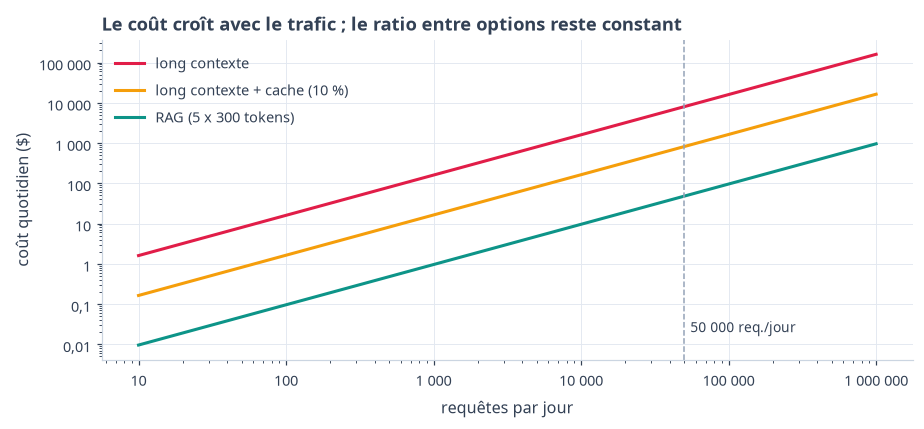

In [3]:
Rs = np.logspace(1, 6, 100)
fig, ax = plt.subplots(figsize=(8.5, 4))
for (nom, c), col in zip(lignes.items(), [ROSE, AMBER, TEAL]):
    ax.loglog(Rs, c * Rs, color=col, label=nom)
ax.axvline(R, color=GRAY, ls="--", lw=1); ax.text(R * 1.1, 2e-2, "50 000 req./jour", fontsize=9)
ax.set_xlabel("requêtes par jour"); ax.set_ylabel("coût quotidien ($)")
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_title("Le coût croît avec le trafic ; le ratio entre options reste constant"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** À trafic élevé, le « tout dans le contexte » coûte des ordres de grandeur
> plus cher qu'un RAG (×170 ici, ×17 avec cache) et impose des secondes de pré-remplissage.
> L'indexation d'un RAG est un coût fixe, généralement négligeable.

## Exercice 6.2 : TF-IDF et BM25 à la main

**Énoncé.** Mini-corpus de 4 documents déjà tokenisés :

- D1 : « chat noir dort »
- D2 : « chat chat chat chat chat chat chat chat chat chat » (bourrage de mots-clés)
- D3 : « chien noir aboie fort la nuit dans le jardin du voisin »
- D4 : « oiseau chante »

1. Calculer l'IDF du livre ($\log N / C(t)$) des termes « chat » et « noir », puis les scores
   TF-IDF des 4 documents pour la requête « chat noir ».
2. Calculer les scores BM25 (variante Lucene, $\mathrm{IDF} = \log(1 + \frac{N - n + 0{,}5}{n + 0{,}5})$,
   $k_1 = 1{,}2$, $b = 0{,}75$).
3. Quel document gagne avec chaque méthode ? Commenter le bourrage de mots-clés.

**Rappels.** Section *Term-based retrieval* : TF-IDF $= \sum_t \mathrm{IDF}(t)\,f(t, D)$. BM25
sature la fréquence ($k_1$) et normalise par la longueur ($b$) :
$\sum_t \mathrm{IDF}(t)\,\frac{f\,(k_1+1)}{f + k_1(1 - b + b\,|D|/\mathrm{avgdl})}$.

**Solution.**

1. $N = 4$ ; « chat » est dans D1 et D2 : $\mathrm{IDF} = \log 2 \approx 0{,}693$ ; « noir »
   dans D1 et D3 : $\log 2 \approx 0{,}693$. TF-IDF : D1 $= 0{,}693 + 0{,}693 = 1{,}386$ ;
   D2 $= 10 \times 0{,}693 = 6{,}93$ ; D3 $= 0{,}693$ ; D4 $= 0$. **D2 gagne** largement.
2. Longueurs 3, 10, 11, 2 ; avgdl $= 6{,}5$. IDF Lucene pour $n = 2$ :
   $\log(1 + 2{,}5/2{,}5) = \log 2 \approx 0{,}693$. Pour D1 ($|D| = 3$) :
   $K = 1{,}2\,(0{,}25 + 0{,}75 \times 3/6{,}5) \approx 0{,}715$ ; chaque terme ($f = 1$) apporte
   $0{,}693 \times 2{,}2 / 1{,}715 \approx 0{,}889$, total $\approx 1{,}778$. Pour D2
   ($|D| = 10$, $f = 10$) : $K = 1{,}2\,(0{,}25 + 0{,}75 \times 10/6{,}5) \approx 1{,}685$ ;
   $0{,}693 \times 22 / 11{,}685 \approx 1{,}305$. Pour D3 ($|D| = 11$, « noir » seul) :
   $K \approx 1{,}823$, $0{,}693 \times 2{,}2 / 2{,}823 \approx 0{,}540$.
3. Avec BM25, **D1 gagne** (il contient les deux termes) : la saturation borne le gain du
   terme répété à $\mathrm{IDF} \times (k_1 + 1) = 1{,}52$ au plus, quel que soit $f$. Le
   TF-IDF naïf récompense linéairement la répétition, ce qui le rend vulnérable au bourrage de
   mots-clés (une technique historique de « référencement abusif »). $\blacksquare$

In [4]:
mini = [["chat", "noir", "dort"], ["chat"] * 10, "chien noir aboie fort la nuit dans le jardin du voisin".split(), ["oiseau", "chante"]]
q = ["chat", "noir"]
tfidf = c6.TfIdf(mini).scores(q)
bm = c6.BM25(mini, k1=1.2, b=0.75, variant="lucene").scores(q)
okapi = c6.BM25(mini, k1=1.2, b=0.75).scores(q)
ref = BM25Okapi(mini, k1=1.2, b=0.75).get_scores(q)
pd.DataFrame({"TF-IDF (livre)": tfidf, "BM25 Lucene": bm, "BM25 Okapi (maison)": okapi, "rank_bm25": ref},
             index=["D1", "D2", "D3", "D4"]).round(3)

,TF-IDF (livre),BM25 Lucene,BM25 Okapi (maison),rank_bm25
D1,1.386,1.778,0.0,0.0
D2,6.931,1.305,0.0,0.0
D3,0.693,0.540,0.0,0.0
D4,0.000,0.000,0.0,0.0


**Vérification.** Les valeurs calculées à la main sont retrouvées. Remarque instructive : avec
la variante Okapi, l'IDF de « chat » et de « noir » vaut $\log(2{,}5/2{,}5) = 0$, car chacun
figure dans exactement la moitié des documents. Elle n'est pas négative, donc `rank_bm25` ne
la remplace pas : **tous les scores sont nuls** et la recherche ne départage rien. C'est un
piège des tout petits corpus (ou des termes très fréquents), que la variante Lucene, toujours
positive, évite. Traçons l'effet de la répétition.

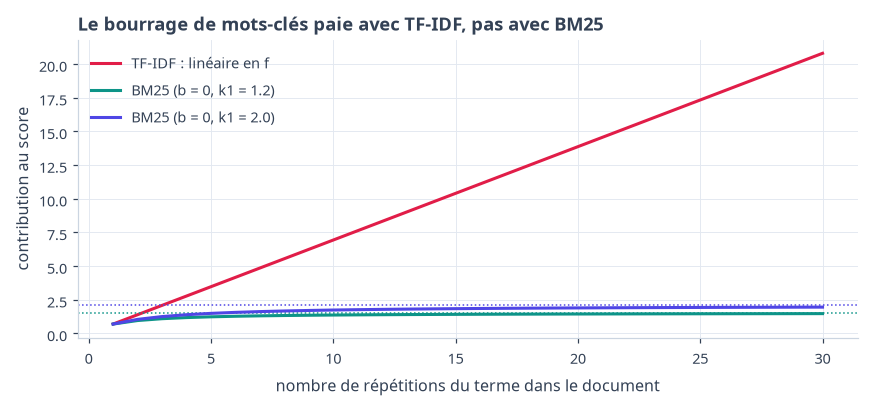

In [5]:
f = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(f, np.log(2) * f, color=ROSE, label="TF-IDF : linéaire en f")
for k1, col in [(1.2, TEAL), (2.0, INDIGO)]:
    ax.plot(f, np.log(2) * f * (k1 + 1) / (f + k1), color=col, label=f"BM25 (b = 0, k1 = {k1})")
    ax.axhline(np.log(2) * (k1 + 1), color=col, ls=":", lw=1)
ax.set_xlabel("nombre de répétitions du terme dans le document"); ax.set_ylabel("contribution au score")
ax.set_title("Le bourrage de mots-clés paie avec TF-IDF, pas avec BM25"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** TF-IDF naïf : un terme répété $f$ fois compte $f$ fois. BM25 borne cette
> contribution à $\mathrm{IDF}\,(k_1 + 1)$ et pénalise les documents longs : il est plus robuste
> aux répétitions et au bourrage.

## Exercice 6.3 : Dimensionner un index vectoriel

**Énoncé.** On indexe $N = 5 \cdot 10^7$ passages avec des embeddings de dimension $d = 768$.

1. Mémoire d'un index exact en float32, puis en float16.
2. Avec une quantification par produit (PQ) à $m = 96$ sous-vecteurs codés sur 8 bits ?
3. Avec IVF à $n_{\text{list}} = 2^{16}$ cellules et `nprobe` = 32 : nombre moyen de vecteurs
   par cellule et nombre de distances calculées par requête, comparé à la force brute.
4. HNSW stocke en plus environ $2M$ voisins (entiers de 4 octets) par vecteur dans la couche
   basse. Surcoût mémoire pour $M = 32$ ?
5. Vérifier les formules de mémoire à petite échelle avec FAISS.

**Rappels.** Section *Embedding-based retrieval* : IVF regroupe les vecteurs par k-means et ne
visite que les cellules proches ; PQ découpe chaque vecteur en sous-vecteurs remplacés par
l'indice d'un centroïde ; HNSW est un graphe hiérarchique de voisinage.

**Solution.**

1. float32 : $4Nd = 4 \times 5\cdot10^7 \times 768 \approx 1{,}54 \cdot 10^{11}$ octets
   $\approx 154$ Go ; float16 : 77 Go.
2. PQ : $m = 96$ octets par vecteur, soit $4{,}8$ Go (compression ×32), plus les livres de
   codes, négligeables ($96 \times 256 \times 8 \times 4$ octets $\approx 0{,}8$ Mo).
3. $5\cdot10^7 / 65\,536 \approx 763$ vecteurs par cellule (dans la fourchette 100 à 10 000
   citée par le livre). Distances par requête : $65\,536$ centroïdes $+ 32 \times 763 \approx
   90\,000$, contre $5 \cdot 10^7$ en force brute : environ **550 fois moins**.
4. $2M \times 4 = 256$ octets par vecteur, soit $12{,}8$ Go de plus, à ajouter aux 154 Go des
   vecteurs : HNSW est rapide mais gourmand. $\blacksquare$

In [6]:
N, d = 5e7, 768
nlist, nprobe = 2 ** 16, 32
memo = pd.Series({"Flat float32": 4 * N * d, "Flat float16": 2 * N * d, "PQ (m = 96)": 96 * N,
                  "HNSW (M = 32), graphe seul": 2 * 32 * 4 * N, "HNSW (M = 32), total": 4 * N * d + 2 * 32 * 4 * N}) / 1e9
print(memo.round(1).to_string(), "\n")
print(f"IVF : {N / nlist:.0f} vecteurs par cellule ; {nlist + nprobe * N / nlist:,.0f} distances / requête "
      f"(force brute : {N:,.0f}, gain x{N / (nlist + nprobe * N / nlist):.0f})".replace(",", " "))

Flat float32                  153.6
Flat float16                   76.8
PQ (m = 96)                     4.8
HNSW (M = 32), graphe seul     12.8
HNSW (M = 32), total          166.4 

IVF : 763 vecteurs par cellule ; 89 950 distances / requête (force brute : 50 000 000  gain x556)


**Vérification** à petite échelle : on construit les index sur $n = 20\,000$ vecteurs de
dimension 768 et on compare leur taille sérialisée aux formules.

               mesuré (Mo)  formule (Mo)
Flat                  61.4          61.4
PQ (m = 96)            2.7           2.7
HNSW (M = 32)         66.9          66.6


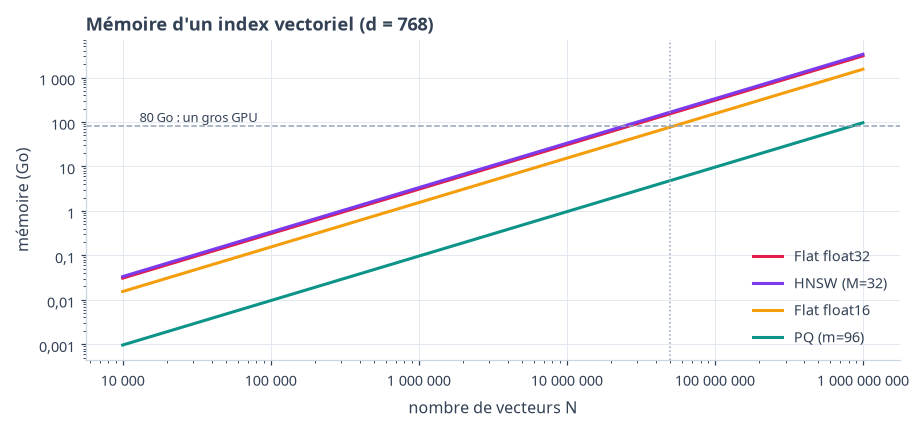

In [7]:
rng = np.random.default_rng(0)
n_, d_ = 20_000, 768
X = rng.normal(size=(n_, d_)).astype("float32")
faiss.omp_set_num_threads(8)
flat = faiss.IndexFlatL2(d_); flat.add(X)
pq = faiss.IndexPQ(d_, 96, 8); pq.train(X); pq.add(X)
hnsw = faiss.IndexHNSWFlat(d_, 32); hnsw.add(X)
mes = pd.DataFrame({
    "mesuré (Mo)": [len(faiss.serialize_index(i_)) / 1e6 for i_ in (flat, pq, hnsw)],
    "formule (Mo)": [4 * n_ * d_ / 1e6, (96 * n_ + 96 * 256 * (d_ // 96) * 4) / 1e6, (4 * n_ * d_ + 2 * 32 * 4 * n_) / 1e6]},
    index=["Flat", "PQ (m = 96)", "HNSW (M = 32)"])
print(mes.round(1))
Ns = np.logspace(4, 9, 50)
fig, ax = plt.subplots(figsize=(8.5, 4))
for nom, per, col in [("Flat float32", 4 * d, ROSE), ("HNSW (M=32)", 4 * d + 256, VIOLET), ("Flat float16", 2 * d, AMBER), ("PQ (m=96)", 96, TEAL)]:
    ax.loglog(Ns, Ns * per / 1e9, color=col, label=nom)
ax.axhline(80, color=GRAY, ls="--", lw=1); ax.text(1.3e4, 100, "80 Go : un gros GPU", fontsize=8.5, color=SLATE)
ax.axvline(N, color=GRAY, ls=":", lw=1)
ax.set_xlabel("nombre de vecteurs N"); ax.set_ylabel("mémoire (Go)")
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_title("Mémoire d'un index vectoriel (d = 768)"); ax.legend()
plt.tight_layout(); plt.show()

Les mesures collent aux formules, à quelques métadonnées près. À $n = 20\,000$, les livres de
codes de PQ (0,8 Mo, inclus dans la formule) pèsent encore autant que la moitié des codes ; à
50 millions de vecteurs, ils deviennent négligeables. Pour HNSW, les couches supérieures du
graphe ajoutent très peu.

> **À retenir.** Mémoire d'un index exact : $4Nd$ octets. PQ compresse d'un facteur
> $4d/m$ ; IVF divise le calcul par environ $N / (n_{\text{list}} + \text{nprobe}\,N/n_{\text{list}})$ ;
> HNSW ajoute environ $8M$ octets par vecteur pour le graphe.

## Exercice 6.4 : Métriques de recherche à la main

**Énoncé.** Un retriever renvoie, pour trois requêtes, les classements ci-dessous (notes de
pertinence entre parenthèses, 0 si non pertinent) :

- q1 : d3 (2), d7 (0), d1 (1), d9 (0), d4 (0) ; pertinents : d3 (2), d1 (1), d5 (1) ;
- q2 : d2 (0), d6 (0), d8 (1), d5 (0), d1 (0) ; pertinent : d8 (1) ;
- q3 : d4 (1), d2 (1), d6 (0), d3 (0), d9 (0) ; pertinents : d4 (1), d2 (1).

Calculer pour chaque requête P@3, R@3, RR, AP et NDCG@3 (gains linéaires), puis les moyennes.

**Rappels.** Section *Comparing retrieval algorithms* et cours 2 : $P@k$, $R@k$ ;
$\mathrm{RR} = 1/\text{rang du premier pertinent}$ ; $\mathrm{AP} = \frac{1}{|\mathcal P|}\sum_{i:\,d_i \in \mathcal P} P@i$ ;
$\mathrm{NDCG@k} = \mathrm{DCG@k}/\mathrm{IDCG@k}$ avec $\mathrm{DCG} = \sum_i g_i / \log_2(i+1)$.

**Solution.**

- **q1** : top-3 = d3, d7, d1 ; 2 pertinents sur 3 : $P@3 = 2/3$, $R@3 = 2/3$ ; RR $= 1$ ;
  AP $= (1/1 + 2/3)/3 = 0{,}556$ (d5 jamais retrouvé compte pour 0). DCG $= 2/1 + 0 + 1/2 = 2{,}5$ ;
  idéal (2, 1, 1) : IDCG $= 2 + 1/\log_2 3 + 1/2 = 3{,}131$ ; NDCG@3 $= 0{,}798$.
- **q2** : d8 au rang 3 : $P@3 = 1/3$, $R@3 = 1$, RR $= 1/3$, AP $= 1/3$ ;
  DCG $= 1/\log_2 4 = 0{,}5$, IDCG $= 1$, NDCG@3 $= 0{,}5$.
- **q3** : d4, d2 aux rangs 1 et 2 : $P@3 = 2/3$, $R@3 = 1$, RR $= 1$, AP $= 1$, NDCG@3 $= 1$.

Moyennes : P@3 $= 0{,}556$, R@3 $= 0{,}889$, MRR $= 0{,}778$, MAP $= 0{,}630$,
NDCG@3 $= 0{,}766$. $\blacksquare$

In [8]:
runs = {"q1": (["d3", "d7", "d1", "d9", "d4"], {"d3": 2, "d1": 1, "d5": 1}),
        "q2": (["d2", "d6", "d8", "d5", "d1"], {"d8": 1}),
        "q3": (["d4", "d2", "d6", "d3", "d9"], {"d4": 1, "d2": 1})}
m = pd.DataFrame({qid: {"P@3": c6.precision_at_k(r, rel, 3), "R@3": c6.recall_at_k(r, rel, 3),
                        "RR": c6.reciprocal_rank(r, rel), "AP": c6.average_precision(r, rel),
                        "NDCG@3": c6.ndcg_at_k(r, rel, 3)} for qid, (r, rel) in runs.items()}).T
m.loc["moyenne"] = m.mean()
m.round(3)

,P@3,R@3,RR,AP,NDCG@3
q1,0.667,0.667,1.000,0.556,0.798
q2,0.333,1.000,0.333,0.333,0.500
q3,0.667,1.000,1.000,1.000,1.000
moyenne,0.556,0.889,0.778,0.630,0.766


**Vérification graphique** : comment ces métriques réagissent quand on déplace le seul
document pertinent de q2 du rang 1 au rang 5 ?

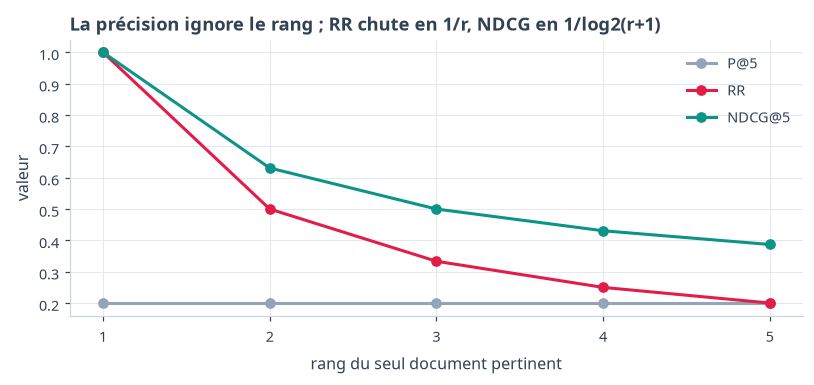

In [9]:
rangs = np.arange(1, 6)
vals = {"P@5": [], "RR": [], "NDCG@5": []}
for r_ in rangs:
    lst = ["x"] * 5
    lst[r_ - 1] = "d8"
    vals["P@5"].append(c6.precision_at_k(lst, {"d8": 1}, 5))
    vals["RR"].append(c6.reciprocal_rank(lst, {"d8": 1}))
    vals["NDCG@5"].append(c6.ndcg_at_k(lst, {"d8": 1}, 5))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (k_, v), col in zip(vals.items(), [GRAY, ROSE, TEAL]):
    ax.plot(rangs, v, marker="o", color=col, label=k_)
ax.set_xlabel("rang du seul document pertinent"); ax.set_ylabel("valeur"); ax.set_xticks(rangs)
ax.set_title("La précision ignore le rang ; RR chute en 1/r, NDCG en 1/log2(r+1)"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** P@k et R@k ignorent l'ordre ; RR ne regarde que le premier pertinent ; AP
> et NDCG récompensent tous les pertinents bien classés, NDCG acceptant des notes graduées avec
> une pénalité logarithmique douce.

## Exercice 6.5 : RRF contre fusion linéaire

**Énoncé.**

1. Montrer que RRF est **invariant** à toute transformation strictement croissante des scores
   d'un retriever, et que la fusion linéaire de scores normalisés min-max ne l'est pas.
   Vérifier en remplaçant les scores BM25 par leur exponentielle.
2. Au cours 2, la fusion linéaire avec $\alpha = 0{,}3$ avait le meilleur MRR, mais $\alpha$ était
   choisi sur les questions de test. Estimer honnêtement sa performance par **validation
   croisée** à deux plis, et comparer à RRF.
3. Que devient RRF quand $k \to \infty$ ?

**Rappels.** Section *Combining retrieval algorithms* : $\mathrm{RRF}(D) = \sum_i 1/(k + r_i(D))$.
Fusion linéaire : $s(D) = \alpha\,\tilde s_{\text{BM25}}(D) + (1 - \alpha)\,\tilde s_{\text{dense}}(D)$,
où $\tilde s$ est le score normalisé min-max.

**Solution.**

1. Une transformation strictement croissante $g$ ne change pas l'ordre des documents, donc
   aucun rang $r_i(D)$ : le score RRF est inchangé. La normalisation min-max, elle, n'est
   invariante que par transformation **affine** : avec $g = \exp$, les écarts entre scores sont
   déformés (le meilleur document écrase les autres), donc la somme pondérée change et le
   classement fusionné peut changer.
2. On découpe les 42 questions en deux moitiés (A, B) ; on choisit $\alpha$ sur A et on mesure
   sur B, puis l'inverse ; la moyenne des deux mesures est une estimation non biaisée.
3. Pour $k \gg r$, $\frac{1}{k + r} \approx \frac{1}{k} - \frac{r}{k^2}$ : classer par RRF revient à
   classer par $-\sum_i r_i(D)$, c'est-à-dire par **somme des rangs** (méthode de Borda), tous les
   rangs comptant autant. Un petit $k$ donne au contraire un poids énorme au premier rang. $\blacksquare$

In [10]:
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)
S_bm = {q["qid"]: bm25.scores(q["question"]) for q in Q}
S_de = {q["qid"]: dense.scores(q["question"]) for q in Q}

def fusion_lin(alpha, g=lambda x: x, qs=Q):
    return {q["qid"]: c6.rank(alpha * c6.minmax(g(S_bm[q["qid"]])) + (1 - alpha) * c6.minmax(S_de[q["qid"]]), IDS, 10) for q in qs}

def fusion_rrf(g=lambda x: x, k=60, qs=Q):
    return {q["qid"]: [d_ for d_, _ in c6.rrf([c6.rank(g(S_bm[q["qid"]]), IDS, 20), c6.rank(S_de[q["qid"]], IDS, 20)], k)][:10] for q in qs}

g_exp = lambda x: np.exp(x)  # noqa: E731  transformation strictement croissante
print("RRF       : MRR = {:.3f} (scores bruts)  /  {:.3f} (exp des scores)".format(
    c6.evaluate(fusion_rrf(), k=10)["MRR"], c6.evaluate(fusion_rrf(g_exp), k=10)["MRR"]))
print("Linéaire  : MRR = {:.3f} (scores bruts)  /  {:.3f} (exp des scores), alpha = 0,3".format(
    c6.evaluate(fusion_lin(0.3), k=10)["MRR"], c6.evaluate(fusion_lin(0.3, g_exp), k=10)["MRR"]))

RRF       : MRR = 0.839 (scores bruts)  /  0.839 (exp des scores)
Linéaire  : MRR = 0.909 (scores bruts)  /  0.866 (exp des scores), alpha = 0,3


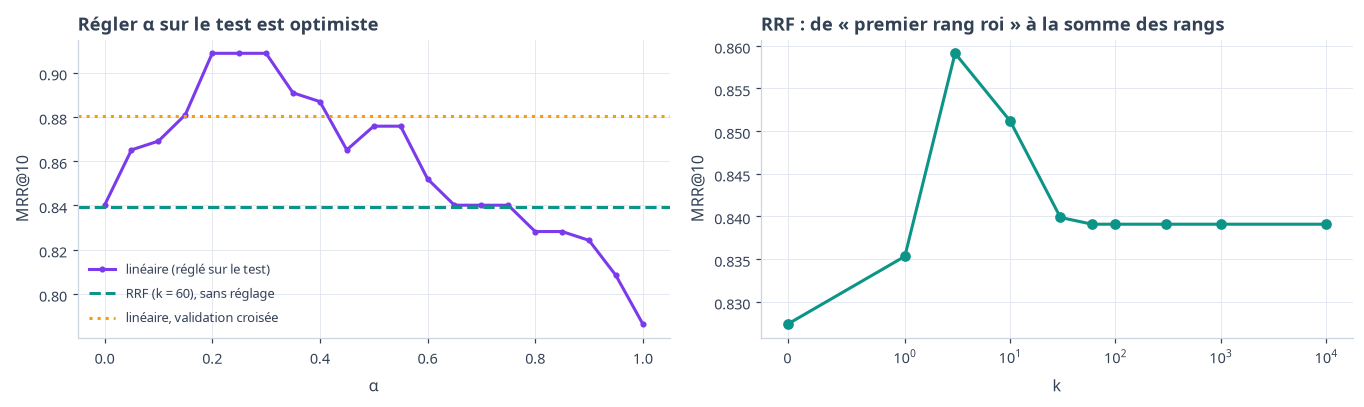

Validation croisée : alpha choisi = 0.24 ± 0.08, MRR test = 0.880 ± 0.036


In [11]:
alphas = np.linspace(0, 1, 21)
rng = np.random.default_rng(0)
cv = []
for rep in range(20):  # 20 découpages aléatoires en deux plis
    perm = rng.permutation(len(Q))
    A, Bq = [Q[i] for i in perm[:21]], [Q[i] for i in perm[21:]]
    for tr, te in [(A, Bq), (Bq, A)]:
        best = max(alphas, key=lambda a: c6.evaluate(fusion_lin(a, qs=tr), tr, k=10)["MRR"])
        cv.append((best, c6.evaluate(fusion_lin(best, qs=te), te, k=10)["MRR"]))
cv = np.array(cv)
courbe = [c6.evaluate(fusion_lin(a), k=10)["MRR"] for a in alphas]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].plot(alphas, courbe, marker="o", ms=3, color=VIOLET, label="linéaire (réglé sur le test)")
axes[0].axhline(c6.evaluate(fusion_rrf(), k=10)["MRR"], color=TEAL, ls="--", label="RRF (k = 60), sans réglage")
axes[0].axhline(cv[:, 1].mean(), color=AMBER, ls=":", lw=2, label="linéaire, validation croisée")
axes[0].set_xlabel("α"); axes[0].set_ylabel("MRR@10"); axes[0].set_title("Régler α sur le test est optimiste"); axes[0].legend(fontsize=8.5)
ks = [0, 1, 3, 10, 30, 60, 100, 300, 1000, 10000]
axes[1].plot(ks, [c6.evaluate(fusion_rrf(k=k_), k=10)["MRR"] for k_ in ks], marker="o", color=TEAL)
axes[1].set_xscale("symlog", linthresh=1); axes[1].set_xlabel("k"); axes[1].set_ylabel("MRR@10")
axes[1].set_title("RRF : de « premier rang roi » à la somme des rangs")
finish(fig); plt.show()
print(f"Validation croisée : alpha choisi = {cv[:, 0].mean():.2f} ± {cv[:, 0].std():.2f}, MRR test = {cv[:, 1].mean():.3f} ± {cv[:, 1].std():.3f}")

**Vérification.** RRF donne exactement le même MRR avec les scores bruts ou exponentiés, alors
que la fusion linéaire change. La validation croisée donne un MRR inférieur à celui obtenu en
réglant $\alpha$ sur le test : une partie de l'avantage apparent venait du sur-apprentissage
du réglage. Sur ce corpus, la fusion linéaire bien réglée reste toutefois devant RRF, avec une
variance notable (21 questions par pli, c'est peu). Conclusion pratique : RRF est un excellent
défaut sans réglage ; une fusion pondérée peut faire mieux si l'on dispose d'assez de questions
annotées pour régler $\alpha$ sur un jeu de validation.

> **À retenir.** RRF n'utilise que les rangs : invariant aux échelles de scores et sans
> paramètre sensible. Tout hyperparamètre de fusion doit être réglé sur des données distinctes
> de celles qui servent à l'évaluation.

## Exercice 6.6 : Taille des morceaux à budget de contexte fixé

**Énoncé.** Le générateur accepte au plus **350 tokens** de contexte récupéré. On découpe le
corpus en morceaux de $s$ mots ($s \in \{15, 25, 40, 60, 90, 140\}$) avec 20 % de chevauchement.
Pour chaque $s$, on récupère par recherche hybride (RRF de BM25 et du dense) **autant de
morceaux que le budget le permet**, et l'on mesure la proportion de questions dont la réponse
(extrait-clé) figure entière dans un des morceaux retenus.

1. Prédire qualitativement la forme de la courbe.
2. Mesurer et commenter. Combien d'embeddings faut-il calculer pour chaque $s$ ?

**Rappels.** Section *Chunking strategy* : de petits morceaux permettent d'en mettre plus dans
le contexte (plus de diversité) mais coupent l'information et multiplient les vecteurs à
indexer ; de gros morceaux gaspillent le budget avec du texte inutile.

**Solution (prédiction).** On attend une courbe en cloche : à $s$ très petit, les extraits-clés
sont souvent coupés et chaque morceau porte peu de contexte (la recherche les trouve mal) ; à $s$
très grand, le budget ne laisse passer qu'un ou deux morceaux, et une erreur de classement ne
se rattrape plus. Le nombre de morceaux, donc d'embeddings, varie comme $1/(0{,}8\,s)$.

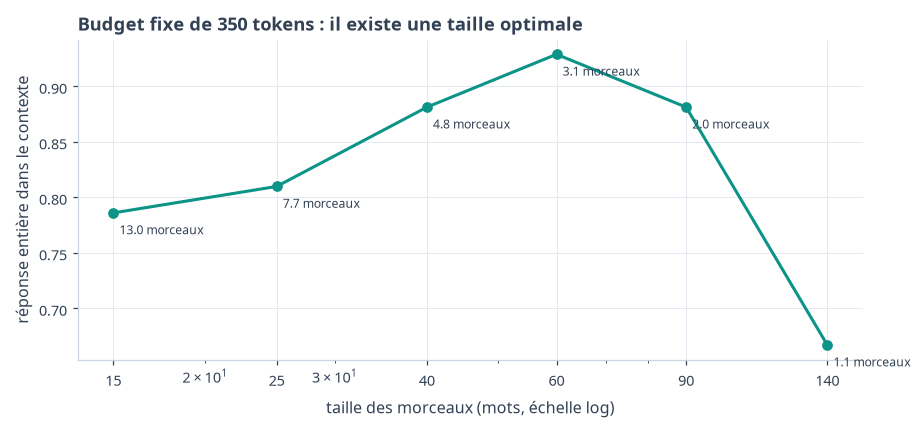

,taille (mots),morceaux indexés,morceaux dans le budget,Hit
0,15,212,13.048,0.786
1,25,128,7.738,0.810
2,40,83,4.810,0.881
3,60,55,3.095,0.929
4,90,37,2.000,0.881
5,140,26,1.143,0.667


In [12]:
qtok = AutoTokenizer.from_pretrained(llm.SMALL)
ntok = lambda t: len(qtok(t)["input_ids"])  # noqa: E731
budget = 350
rows = []
for s in [15, 25, 40, 60, 90, 140]:
    tx, ids, _ = c6.make_chunks(lambda t_, s=s: c6.chunk_words(t_, s, max(1, s // 5)))
    T2 = dict(zip(ids, tx))
    rb, rd = c6.TermRetriever(tx, ids), c6.DenseRetriever(tx, ids)
    hits, nks = [], []
    for q in Q:
        ranked = [d_ for d_, _ in c6.rrf([rb.search(q["question"], 30), rd.search(q["question"], 30)])]
        kept, used = [], 0
        for d_ in ranked:
            c_ = ntok(T2[d_])
            if used + c_ > budget:
                break
            kept.append(d_); used += c_
        relc = c6.chunk_relevance(tx, ids, q["key"])
        hits.append(any(d_ in relc for d_ in kept)); nks.append(len(kept))
    rows.append({"taille (mots)": s, "morceaux indexés": len(tx), "morceaux dans le budget": np.mean(nks), "Hit": np.mean(hits)})
res66 = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(res66["taille (mots)"], res66["Hit"], marker="o", color=TEAL)
for _, r_ in res66.iterrows():
    ax.annotate(f"{r_['morceaux dans le budget']:.1f} morceaux", (r_["taille (mots)"], r_["Hit"]), xytext=(4, -14),
                textcoords="offset points", fontsize=8, color=SLATE)
ax.set_xscale("log"); ax.set_xticks(res66["taille (mots)"]); ax.set_xticklabels(res66["taille (mots)"])
ax.set_xlabel("taille des morceaux (mots, échelle log)"); ax.set_ylabel("réponse entière dans le contexte")
ax.set_title(f"Budget fixe de {budget} tokens : il existe une taille optimale"); plt.tight_layout(); plt.show()
res66.round(3)

**Vérification.** La courbe confirme le compromis : les tout petits morceaux coupent les
extraits-clés (et l'index compte plusieurs fois plus de vecteurs), les gros ne laissent passer
qu'un ou deux morceaux. L'optimum se situe à des tailles intermédiaires, proches de la longueur
naturelle d'un paragraphe de notre corpus (40 à 60 mots). Sur un autre corpus, l'optimum sera
ailleurs : c'est une mesure à refaire.

> **À retenir.** À budget de contexte fixé, la taille des morceaux arbitre entre **couverture**
> (nombre de morceaux) et **intégrité** (information non coupée). L'optimum se mesure ; il
> dépend du corpus, du retriever et du budget.

In [13]:
c6.free_models()